# Monte Carlo: productivity shocks (CRS, FIGARO network)

Under CRS, a productivity shock $\eta$ gives, exactly: $\ln p=-L^\top\eta$, revenue $s=v$ (unchanged), $y=v\odot e^{L^\top\eta}$, $\ln U=v'\eta$.
So the simulation needs **one sparse solve per draw** and no identity checks.

**What it does**
1. Draws many shock vectors $\eta$ (iid Gaussian, and country-correlated Gaussian) for a grid of scales $\sigma$.
2. Reports the distribution of welfare, total output, prices; one-sided "disruption vs improvement" experiments; sector-level network amplification.
3. Saves every figure (PNG + PDF) and every table (CSV + LaTeX `tabular`) in `mc_output/`.

**How to run:** put `matrix_eu-ic-io_ind-by-ind_26ed_2024_utf8.csv` next to the notebook and run all cells. Change `R` (replications) in section 1.
The first run builds the model from the CSV (~1 min) and caches it; later runs start in seconds.

In [1]:
# ============================================================
# 0. SETUP  (identical in the three notebooks)
#    Loads FIGARO, builds A_model / gamma / beta, factorizes I-A once.
#    After the first run the model is cached on disk, so reloading is instant.
# ============================================================
from pathlib import Path
import re, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csc_matrix, eye, load_npz, save_npz
from scipy.sparse.linalg import splu

FILE_PATH = Path("matrix_eu-ic-io_ind-by-ind_26ed_2024_utf8.csv")
TARGET_INTERMEDIATE_SHARE = 0.99      # rescaling target for the 3 columns with beta <= 0
OUTPUT_DIR = Path("mc_output"); OUTPUT_DIR.mkdir(exist_ok=True)
A_CACHE, META_CACHE = Path("figaro_A_model.npz"), Path("figaro_meta.npz")

def build_model_from_csv():
    df = pd.read_csv(FILE_PATH, index_col="rowLabels", low_memory=False)
    num = df.apply(pd.to_numeric, errors="coerce")
    labs = [l for l in df.index if re.fullmatch(r"[A-Z]{2}_.+", str(l))
            and not str(l).startswith(("W2_", "FIGW1_")) and l in df.columns]
    x = num.loc[labs, :].sum(axis=1)
    active = x[x > 0].index.tolist()
    Z = num.loc[active, active].to_numpy(float)
    xa = x.loc[active].to_numpy(float)
    A = Z / xa[None, :]
    for j in np.where(1.0 - A.sum(axis=0) <= 0)[0]:          # columns with beta <= 0
        A[:, j] *= TARGET_INTERMEDIATE_SHARE / A[:, j].sum()
    p3 = [c for c in num.columns if str(c).endswith("_P3_S14")]
    hc = np.maximum(num.loc[active, p3].sum(axis=1).to_numpy(float), 0.0)
    return csc_matrix(A), hc / hc.sum(), np.array(active, dtype=str)

if A_CACHE.exists() and META_CACHE.exists() and float(np.load(META_CACHE)["target"]) == TARGET_INTERMEDIATE_SHARE:
    A_sparse = load_npz(A_CACHE).tocsc(); meta = np.load(META_CACHE)
    gamma, labels = meta["gamma"], meta["labels"]
    print("Loaded cached model.")
else:
    t0 = time.time(); A_sparse, gamma, labels = build_model_from_csv()
    save_npz(A_CACHE, A_sparse); np.savez(META_CACHE, gamma=gamma, labels=labels, target=TARGET_INTERMEDIATE_SHARE)
    print(f"Built model from CSV in {time.time()-t0:.0f}s and cached it.")

n = A_sparse.shape[0]
beta = 1.0 - np.asarray(A_sparse.sum(axis=0)).ravel()
I = eye(n, format="csc")
LU_M = splu((I - A_sparse).tocsc())          # solves with L' = (I-A)^{-1}
LU_T = splu((I - A_sparse.T).tocsc())        # solves with L^T = (I-A^T)^{-1}
v = LU_M.solve(gamma)                        # Domar weights  v = L' gamma
h = LU_T.solve(np.ones(n))                   # h_i = sum_j L'_{j,i}: output multiplier of final demand in sector i
sumv = v.sum()
country = np.array([l[:2] for l in labels]); countries, cidx = np.unique(country, return_inverse=True)
pos = gamma > 0
print(f"n = {n} sectors, {len(countries)} countries | sum(gamma) = {gamma.sum():.6f} | beta'v = {beta@v:.6f} | sum(v) = {sumv:.4f} | ||v||_2 = {np.linalg.norm(v):.4f}")

# ---------- small helpers ----------
COL = dict(co="#D55E00", red="#0072B2", grey="#6B6B6B", green="#009E73", purple="#CC79A7")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=200); fig.savefig(OUTPUT_DIR / f"{name}.pdf")
    plt.show()

def to_tex(df, name, float_fmt="{:.4f}", index=False):
    d = df.reset_index() if index else df
    cols = list(d.columns)
    lines = [r"\begin{tabular}{" + "l" * len(cols) + "}", r"\hline",
             " & ".join(str(c).replace("_", r"\_") for c in cols) + r" \\ \hline"]
    for _, r in d.iterrows():
        lines.append(" & ".join(float_fmt.format(r[c]) if isinstance(r[c], (float, np.floating))
                                else str(r[c]).replace("_", r"\_") for c in cols) + r" \\")
    lines += [r"\hline", r"\end{tabular}"]
    (OUTPUT_DIR / f"{name}.tex").write_text("\n".join(lines))
    d.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

def alab(a):  return "prop." if np.isinf(a) else str(int(a))

Built model from CSV in 5s and cached it.
n = 3070 sectors, 49 countries | sum(gamma) = 1.000000 | beta'v = 1.000000 | sum(v) = 1.8695 | ||v||_2 = 0.1569


In [2]:
# ============================================================
# 1. PARAMETERS
# ============================================================
SEED, R, BATCH = 2024, 5000, 250          # R = replications per (sigma, rho) cell
SIGMAS = [0.01, 0.025, 0.05, 0.10]        # std of log-productivity shocks
RHOS   = [0.0, 0.5, 1.0]                  # share of shock variance that is common within a country
SIG_FOCUS = 0.05                          # scale used in the single-scale figures

rng = np.random.default_rng(SEED)
nC = len(countries)
Vc = np.bincount(cidx, weights=v, minlength=nC)      # centrality of each country
v2 = np.linalg.norm(v)

def draw_eta(sigma, rho, B):
    E = rng.standard_normal((n, B))
    if rho == 0.0: return sigma * E
    U = rng.standard_normal((nC, B))
    return sigma * (np.sqrt(rho) * U[cidx] + np.sqrt(1 - rho) * E)

def theory_std_lnU(sigma, rho):                      # exact: lnU = v'eta is linear in eta
    return sigma * np.sqrt(rho * (Vc ** 2).sum() + (1 - rho) * v2 ** 2)

# ============================================================
# 2. MONTE CARLO
# ============================================================
draws, onesided = {}, []
amp1 = np.zeros(n); amp2 = np.zeros(n); amp_n = 0           # sector-level amplification (iid case)
drift_sector = np.zeros(n); drift_n = 0
t0 = time.time()
for sigma in SIGMAS:
    for rho in RHOS:
        out = {k: [] for k in ["lnU", "dY", "pmin", "pmax", "lnp_sd", "worst", "best"]}
        left = R
        while left > 0:
            B = min(BATCH, left); left -= B
            eta = draw_eta(sigma, rho, B)
            Z = LU_T.solve(eta)                          # L^T eta, one column per draw
            Y = np.expm1(Z)                              # sector output change (fraction)
            P = np.exp(-Z)
            out["lnU"].append(v @ eta)
            out["dY"].append(100 * (v @ Y) / sumv)       # total output change, %
            out["pmin"].append(P.min(0)); out["pmax"].append(P.max(0)); out["lnp_sd"].append(Z.std(0))
            out["worst"].append(100 * Y.min(0)); out["best"].append(100 * Y.max(0))
            if rho == 0.0:
                amp1 += (Z / sigma).sum(1); amp2 += ((Z / sigma) ** 2).sum(1); amp_n += B
                if sigma == SIG_FOCUS: drift_sector += Y.sum(1); drift_n += B
        draws[(sigma, rho)] = pd.DataFrame({k: np.concatenate(vv) for k, vv in out.items()})
    # one-sided experiment: all sectors improve (+|eta|) vs all sectors are disrupted (-|eta|)
    up, dn, lu = [], [], []
    left = R
    while left > 0:
        B = min(BATCH, left); left -= B
        Ea = np.abs(rng.standard_normal((n, B)))
        Zp = LU_T.solve(sigma * Ea)
        up.append(100 * (v @ np.expm1(Zp)) / sumv); dn.append(100 * (v @ np.expm1(-Zp)) / sumv); lu.append(sigma * (v @ Ea))
    onesided.append(dict(sigma=sigma, dlnU=np.mean(np.concatenate(lu)),
                         output_gain_pct=np.mean(np.concatenate(up)), output_loss_pct=np.mean(np.concatenate(dn))))
    print(f"sigma={sigma}: done ({time.time()-t0:.0f}s)")

amp = amp2 / amp_n - (amp1 / amp_n) ** 2            # Var[(L^T eta)_i] / sigma^2
drift_sector = 100 * drift_sector / drift_n

# ============================================================
# 3. STATISTICS FOR THE THESIS
# ============================================================
rows = []
for (sigma, rho), d in draws.items():
    U = np.exp(d.lnU.values)
    rows.append(dict(sigma=sigma, rho=rho, mean_lnU=d.lnU.mean(), std_lnU=d.lnU.std(), theory_std_lnU=theory_std_lnU(sigma, rho),
                     P_U_below_1=(U < 1).mean(), P_loss_above_1pct=(U < 0.99).mean(), U_q05=np.quantile(U, 0.05), U_q95=np.quantile(U, 0.95),
                     mean_dY_pct=d.dY.mean(), std_dY_pct=d.dY.std(), mean_pmin=d.pmin.mean(), mean_pmax=d.pmax.mean(),
                     mean_lnp_sd=d.lnp_sd.mean(), mean_worst_sector_pct=d.worst.mean(), mean_best_sector_pct=d.best.mean()))
stats = pd.DataFrame(rows)
os1 = pd.DataFrame(onesided); os1["asymmetry_gain_minus_|loss|_pct"] = os1.output_gain_pct + os1.output_loss_pct
to_tex(stats, "production_mc_stats", "{:.4f}"); to_tex(os1, "production_onesided", "{:.4f}")
print("||v||_2 =", round(v2, 4), "| country-level centrality sum of squares =", round((Vc**2).sum()**.5, 4))
print(stats.round(4).to_string(index=False))
print("\nOne-sided shocks (all sectors improve vs all disrupted, same |eta|):")
print(os1.round(4).to_string(index=False))

sigma=0.01: done (183s)
sigma=0.025: done (368s)
sigma=0.05: done (550s)
sigma=0.1: done (740s)
||v||_2 = 0.1569 | country-level centrality sum of squares = 0.7189
 sigma  rho  mean_lnU  std_lnU  theory_std_lnU  P_U_below_1  P_loss_above_1pct  U_q05  U_q95  mean_dY_pct  std_dY_pct  mean_pmin  mean_pmax  mean_lnp_sd  mean_worst_sector_pct  mean_best_sector_pct
 0.010  0.0   -0.0000   0.0016          0.0016       0.5080             0.0000 0.9974 1.0026       0.0046      0.1459     0.9574     1.0446       0.0110                -4.2694                4.4573
 0.010  0.5   -0.0001   0.0052          0.0052       0.5022             0.0302 0.9913 1.0086       0.0061      0.5207     0.9498     1.0529       0.0137                -5.0131                5.2969
 0.010  1.0   -0.0000   0.0072          0.0072       0.5000             0.0828 0.9881 1.0117       0.0179      0.7151     0.9473     1.0559       0.0160                -5.2808                5.5855
 0.025  0.0   -0.0001   0.0039          0.00

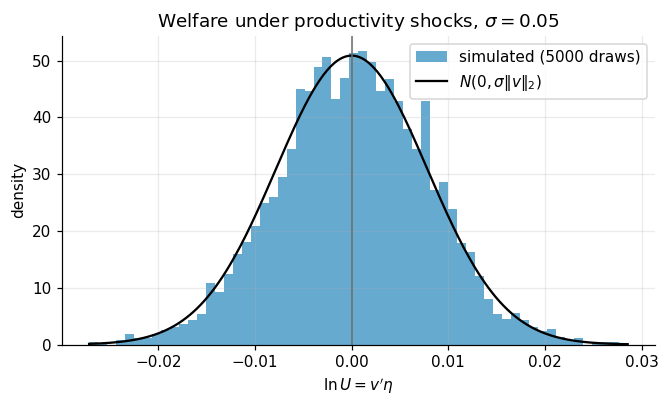

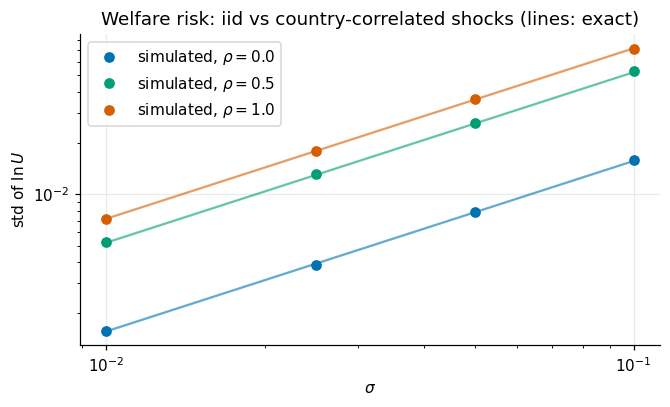

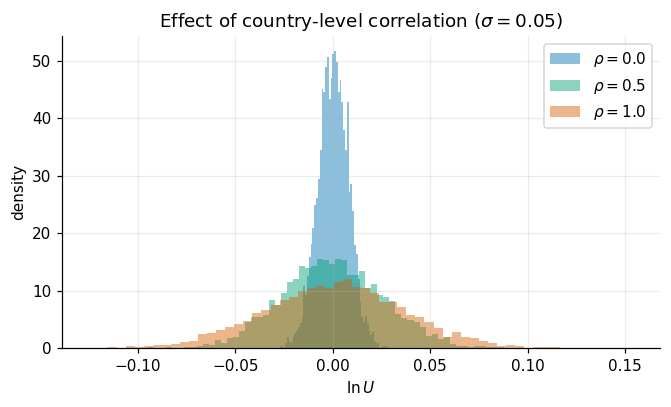

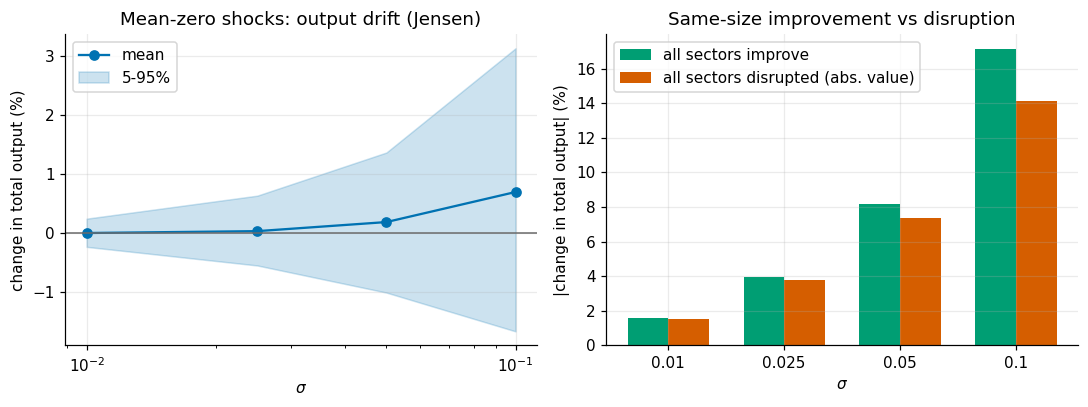

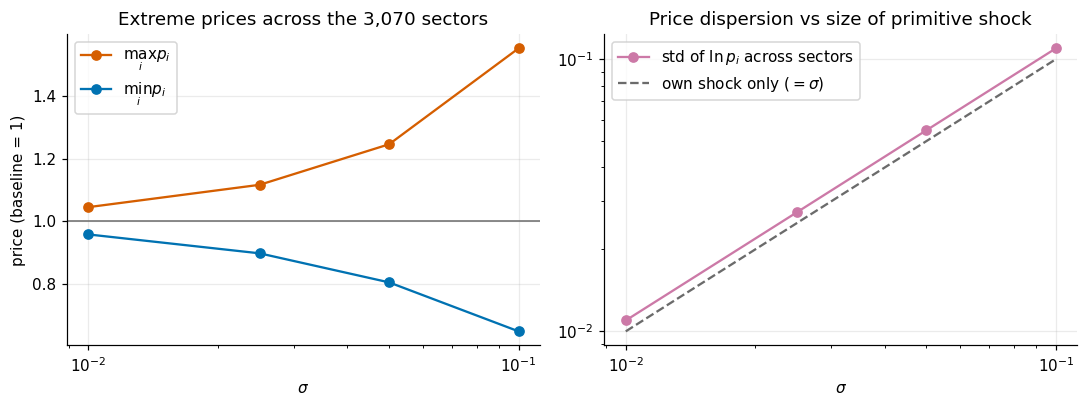

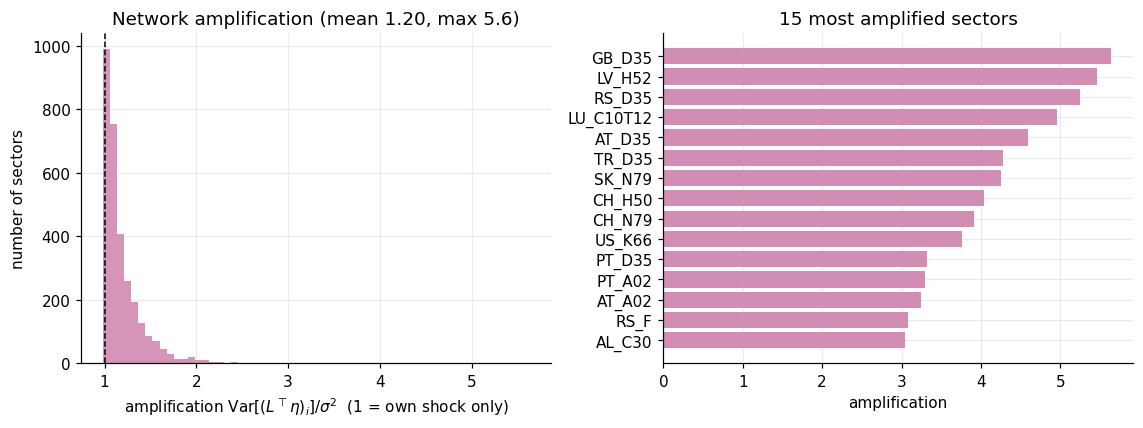

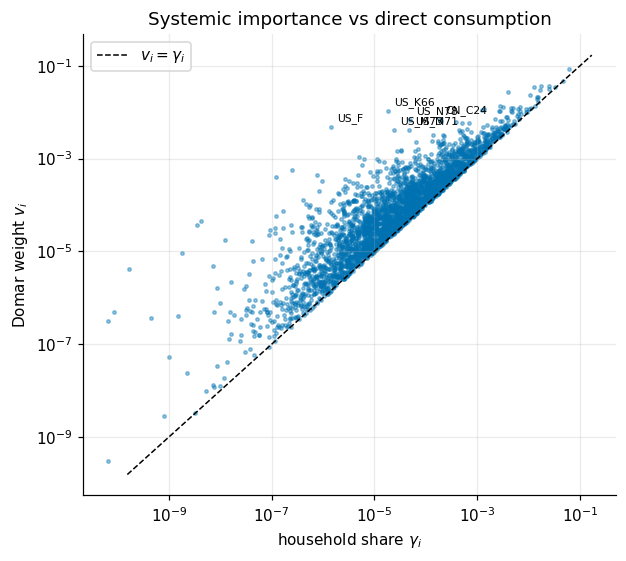

Sectors with gamma<1e-4: 2215 (72%); they hold 4.5% of consumption and 11.6% of total centrality.

All outputs saved in /content/mc_output


In [3]:
# ============================================================
# 4. FIGURES
# ============================================================
# Fig 1 - distribution of welfare, iid shocks, with the exact normal law
d = draws[(SIG_FOCUS, 0.0)]; sd = theory_std_lnU(SIG_FOCUS, 0.0)
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.hist(d.lnU, bins=60, density=True, color=COL["red"], alpha=.6, label=f"simulated ({R} draws)")
xs = np.linspace(d.lnU.min(), d.lnU.max(), 300)
ax.plot(xs, np.exp(-xs**2 / (2*sd**2)) / (sd*np.sqrt(2*np.pi)), color="k", lw=1.5, label=r"$N(0,\sigma\|v\|_2)$")
ax.axvline(0, color=COL["grey"], lw=1); ax.set_xlabel(r"$\ln U = v'\eta$"); ax.set_ylabel("density")
ax.set_title(rf"Welfare under productivity shocks, $\sigma={SIG_FOCUS}$"); ax.legend(); savefig(fig, "prod_fig1_welfare_distribution")

# Fig 2 - dispersion of welfare vs sigma, for different degrees of country-level correlation
fig, ax = plt.subplots(figsize=(6.2, 3.8)); sg = np.array(SIGMAS)
for rho, c in zip(RHOS, [COL["red"], COL["green"], COL["co"]]):
    ax.plot(sg, [draws[(s, rho)].lnU.std() for s in SIGMAS], "o", color=c, label=rf"simulated, $\rho={rho}$")
    ax.plot(sg, [theory_std_lnU(s, rho) for s in SIGMAS], "-", color=c, alpha=.6)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(r"$\sigma$"); ax.set_ylabel(r"std of $\ln U$")
ax.set_title("Welfare risk: iid vs country-correlated shocks (lines: exact)"); ax.legend(); savefig(fig, "prod_fig2_welfare_std_vs_sigma")

# Fig 3 - correlated shocks: welfare distributions at SIG_FOCUS
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for rho, c in zip(RHOS, [COL["red"], COL["green"], COL["co"]]):
    ax.hist(draws[(SIG_FOCUS, rho)].lnU, bins=60, density=True, alpha=.45, color=c, label=rf"$\rho={rho}$")
ax.set_xlabel(r"$\ln U$"); ax.set_ylabel("density"); ax.set_title(rf"Effect of country-level correlation ($\sigma={SIG_FOCUS}$)")
ax.legend(); savefig(fig, "prod_fig3_correlated_shocks")

# Fig 4 - total output: mean and 5-95% band (iid), and one-sided gain/loss asymmetry
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
q = lambda s, a: np.quantile(draws[(s, 0.0)].dY, a)
axs[0].plot(sg, [draws[(s, 0.0)].dY.mean() for s in SIGMAS], "o-", color=COL["red"], label="mean")
axs[0].fill_between(sg, [q(s, .05) for s in SIGMAS], [q(s, .95) for s in SIGMAS], color=COL["red"], alpha=.2, label="5-95%")
axs[0].axhline(0, color=COL["grey"], lw=1); axs[0].set_xscale("log"); axs[0].set_xlabel(r"$\sigma$"); axs[0].set_ylabel("change in total output (%)")
axs[0].set_title("Mean-zero shocks: output drift (Jensen)"); axs[0].legend()
w = 0.35; xi = np.arange(len(SIGMAS))
axs[1].bar(xi - w/2, os1.output_gain_pct, w, color=COL["green"], label="all sectors improve")
axs[1].bar(xi + w/2, -os1.output_loss_pct, w, color=COL["co"], label="all sectors disrupted (abs. value)")
axs[1].set_xticks(xi); axs[1].set_xticklabels([str(s) for s in SIGMAS]); axs[1].set_xlabel(r"$\sigma$"); axs[1].set_ylabel("|change in total output| (%)")
axs[1].set_title("Same-size improvement vs disruption"); axs[1].legend(); savefig(fig, "prod_fig4_output")

# Fig 5 - prices
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
axs[0].plot(sg, [draws[(s, 0.0)].pmax.mean() for s in SIGMAS], "o-", color=COL["co"], label=r"$\max_i p_i$")
axs[0].plot(sg, [draws[(s, 0.0)].pmin.mean() for s in SIGMAS], "o-", color=COL["red"], label=r"$\min_i p_i$")
axs[0].axhline(1, color=COL["grey"], lw=1); axs[0].set_xscale("log"); axs[0].set_xlabel(r"$\sigma$"); axs[0].set_ylabel("price (baseline = 1)")
axs[0].set_title("Extreme prices across the 3,070 sectors"); axs[0].legend()
axs[1].plot(sg, [draws[(s, 0.0)].lnp_sd.mean() for s in SIGMAS], "o-", color=COL["purple"], label="std of $\\ln p_i$ across sectors")
axs[1].plot(sg, sg, "--", color=COL["grey"], label=r"own shock only ($=\sigma$)")
axs[1].set_xscale("log"); axs[1].set_yscale("log"); axs[1].set_xlabel(r"$\sigma$"); axs[1].set_title("Price dispersion vs size of primitive shock"); axs[1].legend()
savefig(fig, "prod_fig5_prices")

# Fig 6 - network amplification, sector level
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4))
axs[0].hist(amp, bins=60, color=COL["purple"], alpha=.8); axs[0].axvline(1, color="k", lw=1, ls="--")
axs[0].set_xlabel(r"amplification $\mathrm{Var}[(L^\top\eta)_i]/\sigma^2$  (1 = own shock only)"); axs[0].set_ylabel("number of sectors")
axs[0].set_title(f"Network amplification (mean {amp.mean():.2f}, max {amp.max():.1f})")
top = np.argsort(-amp)[:15][::-1]
axs[1].barh(labels[top], amp[top], color=COL["purple"], alpha=.85); axs[1].set_xlabel("amplification"); axs[1].set_title("15 most amplified sectors")
savefig(fig, "prod_fig6_amplification")
amp_tab = pd.DataFrame(dict(sector=labels[np.argsort(-amp)[:20]], amplification=np.sort(amp)[::-1][:20],
                            v=v[np.argsort(-amp)[:20]], gamma=gamma[np.argsort(-amp)[:20]]))
to_tex(amp_tab, "production_top_amplified", "{:.5g}")

# Fig 7 - systemic importance: Domar weight v_i vs household share gamma_i
fig, ax = plt.subplots(figsize=(5.8, 5.2)); m = pos
ax.scatter(gamma[m], v[m], s=5, color=COL["red"], alpha=.4)
lim = [v[m].min() * .5, v.max() * 2]; ax.plot(lim, lim, "k--", lw=1, label=r"$v_i=\gamma_i$")
r = np.where(m, v / np.maximum(gamma, 1e-300), 0); big = np.argsort(-(r * (v > 2e-3)))[:6]
for i in big: ax.annotate(labels[i], (gamma[i], v[i]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(r"household share $\gamma_i$"); ax.set_ylabel(r"Domar weight $v_i$")
ax.set_title("Systemic importance vs direct consumption"); ax.legend(); savefig(fig, "prod_fig7_centrality_vs_consumption")
imp = pd.DataFrame(dict(sector=labels, gamma=gamma, v=v, ratio=np.where(pos, v / np.maximum(gamma, 1e-300), np.nan)))
to_tex(imp.sort_values("v", ascending=False).head(20), "production_top_centrality", "{:.5g}")
share_small = v[gamma < 1e-4].sum() / sumv
print(f"Sectors with gamma<1e-4: {(gamma<1e-4).sum()} ({(gamma<1e-4).mean():.0%}); they hold {gamma[gamma<1e-4].sum():.1%} of consumption and {share_small:.1%} of total centrality.")
print("\nAll outputs saved in", OUTPUT_DIR.resolve())